# Outlier detection

This notebook decides how unusual values should be handled in this project. The decision is based on data meaning and temporal cross-validation, not only on how many rows an algorithm flags.

## Principles

- An impossible value is a data error and is handled by a consistency rule.
- An extreme value is not automatically an error. Large purchases and long customer histories may be valid.
- The most recent 20% of the training period remains locked and is not used to choose a method.
- Transformations and outlier detectors are fitted on each training fold only. Validation rows are never removed.
- Rows from `test.csv` are never removed.

## 0. Imports and configuration

In [1]:
import os
import sys
from pathlib import Path

# run from the project root, whether Jupyter was started there or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from minisom import MiniSom
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import DBSCAN, KMeans
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

import classification.preprocessing as classification_prep
import regression.preprocessing as regression_prep
from classification.model import build_model as build_classifier
from regression.model import build_model as build_regressor
from src.cleaning import drop_training_rows, prepare_table
from src.data import load_data, standardize_columns
from src.evaluate import cross_validate_pipeline, paired_comparison, select_scoring, temporal_folds
from src.pipeline import build_pipeline as build_model_pipeline
from src.preprocessing import build_preprocessor, split_dev_test, task_preprocessing_config
from src.tasks import TASKS

warnings.filterwarnings("ignore")

with open("config.yaml", encoding="utf-8") as file:
    config = yaml.safe_load(file)

data_cfg = config["data"]
diag_cfg = config["diagnostics"]
SCORING = {task: select_scoring(TASKS[task].evaluate.SCORING, config[task]["metrics"]) for task in TASKS}

## 1. Load the cleaned development data

The same project functions used by `main.py` apply the cleaning rules. The 65 almost-empty rows are removed. The recent locked period is set aside before any outlier decision is made.

In [2]:
train_raw = load_data(data_cfg["train_path"])
test_raw = load_data(data_cfg["test_path"])
clientes_raw = load_data(data_cfg["clientes_path"])

train_clean, cleaning_report = prepare_table(
    train_raw, config, clientes_raw
)
train_clean, row_report = drop_training_rows(
    train_clean, diag_cfg, data_cfg["id_column"], config["customers"]
)

classification_rows = classification_prep.select_training_rows(
    train_clean, config
)
X, y, extras = classification_prep.prepare_features(
    classification_rows, config
)
X_dev, X_locked, y_dev, y_locked, extras_dev, extras_locked = (
    split_dev_test(
        X, y, extras, config["test_set"], data_cfg["date_column"]
    )
)

print("Raw training rows:", len(train_raw))
print("Rows after cleaning:", len(train_clean))
print("Development rows analysed:", len(X_dev))
print("Locked rows not analysed:", len(X_locked))

Raw training rows: 6534
Rows after cleaning: 6469
Development rows analysed: 5024
Locked rows not analysed: 1286


## 2. Separate data errors from valid extremes

A previous maximum purchase cannot be larger than the sum of all previous purchases. This is a logical error, not a statistical outlier. The rule is now in `config.yaml`; invalid values become missing and the fitted median imputer handles them inside each fold.

In [3]:
def count_impossible_prior_max(raw_data):
    data = standardize_columns(raw_data, diag_cfg["column_renames"])
    is_error = (
        data["prior_purchase_count"].gt(0)
        & data["prior_max_purchase_value"].notna()
        & data["prior_total_spend"].notna()
        & data["prior_max_purchase_value"].gt(
            data["prior_total_spend"] + 0.01
        )
    )
    return int(is_error.sum())

print("Impossible values in train:", count_impossible_prior_max(train_raw))
print("Impossible values in test: ", count_impossible_prior_max(test_raw))

Impossible values in train: 45
Impossible values in test:  6


## 3. Numerical overview

Targets, identifiers and dates are excluded. Only numerical predictors used by the classification recipe are inspected here.

In [4]:
classification_cfg = task_preprocessing_config(config, "classification")
numeric_columns = [
    column for column in classification_cfg["numeric_features"]
    if column in X_dev.columns
]
numeric_data = X_dev[numeric_columns].copy()

print("Numerical columns analysed:", len(numeric_columns))
display(numeric_data.describe().T)

Numerical columns analysed: 26


,count,mean,std,min,25%,50%,75%,max
net_total,5024.0,698.927054,1004.933133,0.76,141.15,357.23,825.0125,11734.48
total_tax,5024.0,138.855016,192.953552,0.0,27.705,74.555,171.395,2698.93
shipping_cost,5024.0,1.228465,6.1044,0.0,0.0,0.0,0.0,181.06
global_discount_total,5024.0,0.307054,5.140932,0.0,0.0,0.0,0.0,218.49
line_discount_total,5024.0,91.684156,253.479282,0.0,0.0,7.455,71.975,3794.51
cost,5024.0,296.356923,452.033447,0.0,43.73,141.038285,360.846419,6111.3
line_item_count,5024.0,20.553145,27.303472,1.0,3.0,10.0,27.0,423.0
invoice_count_current_purchase,5024.0,1.069865,0.32066,1.0,1.0,1.0,1.0,5.0
days_since_previous_purchase,5018.0,89.999801,154.171054,0.0,9.0,42.0,112.0,2524.0
customer_tenure_days,5024.0,866.080016,731.970515,0.0,230.75,737.0,1391.5,2806.0


## 4. IQR and skewness report

The IQR rule is a useful warning signal, not a deletion rule. It is not informative when the IQR is zero, which happens in sparse or almost-constant columns.

In [5]:
report_rows = []

for column in numeric_columns:
    values = numeric_data[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        outlier_count = np.nan
        outlier_percent = np.nan
        status = "Not informative (IQR = 0)"
    else:
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        is_outlier = values.lt(lower) | values.gt(upper)
        outlier_count = int(is_outlier.sum())
        outlier_percent = is_outlier.mean() * 100
        status = "Available"

    report_rows.append({
        "column": column,
        "missing_%": numeric_data[column].isna().mean() * 100,
        "zero_%": values.eq(0).mean() * 100,
        "skewness": values.skew(),
        "iqr_status": status,
        "iqr_outliers": outlier_count,
        "iqr_outlier_%": outlier_percent,
    })

outlier_report = pd.DataFrame(report_rows).set_index("column")
outlier_report["absolute_skewness"] = outlier_report["skewness"].abs()
display(outlier_report.sort_values("absolute_skewness", ascending=False).round(2))

,missing_%,zero_%,skewness,iqr_status,iqr_outliers,iqr_outlier_%,absolute_skewness
column,,,,,,,
global_discount_total,0.00,98.65,29.62,Not informative (IQR = 0),NaN,NaN,29.62
shipping_cost,0.00,81.73,19.39,Not informative (IQR = 0),NaN,NaN,19.39
line_discount_total,0.00,42.16,6.75,Available,657.0,13.08,6.75
invoice_count_current_purchase,0.00,0.00,6.35,Not informative (IQR = 0),NaN,NaN,6.35
prior_mean_gap_days,0.12,19.01,6.02,Available,249.0,4.96,6.02
prior_min_purchase_value,0.00,11.05,5.72,Available,596.0,11.86,5.72
days_since_previous_purchase,0.12,11.06,5.60,Available,301.0,6.00,5.60
prior_std_gap_days,0.00,25.40,5.29,Available,256.0,5.10,5.29
spend_30d,0.00,66.40,4.66,Available,804.0,16.00,4.66


## 5. Inspect the strongest values

The six most skewed predictors are plotted, then their largest values are shown with row identifiers. The identifiers are for investigation only and are not model inputs.

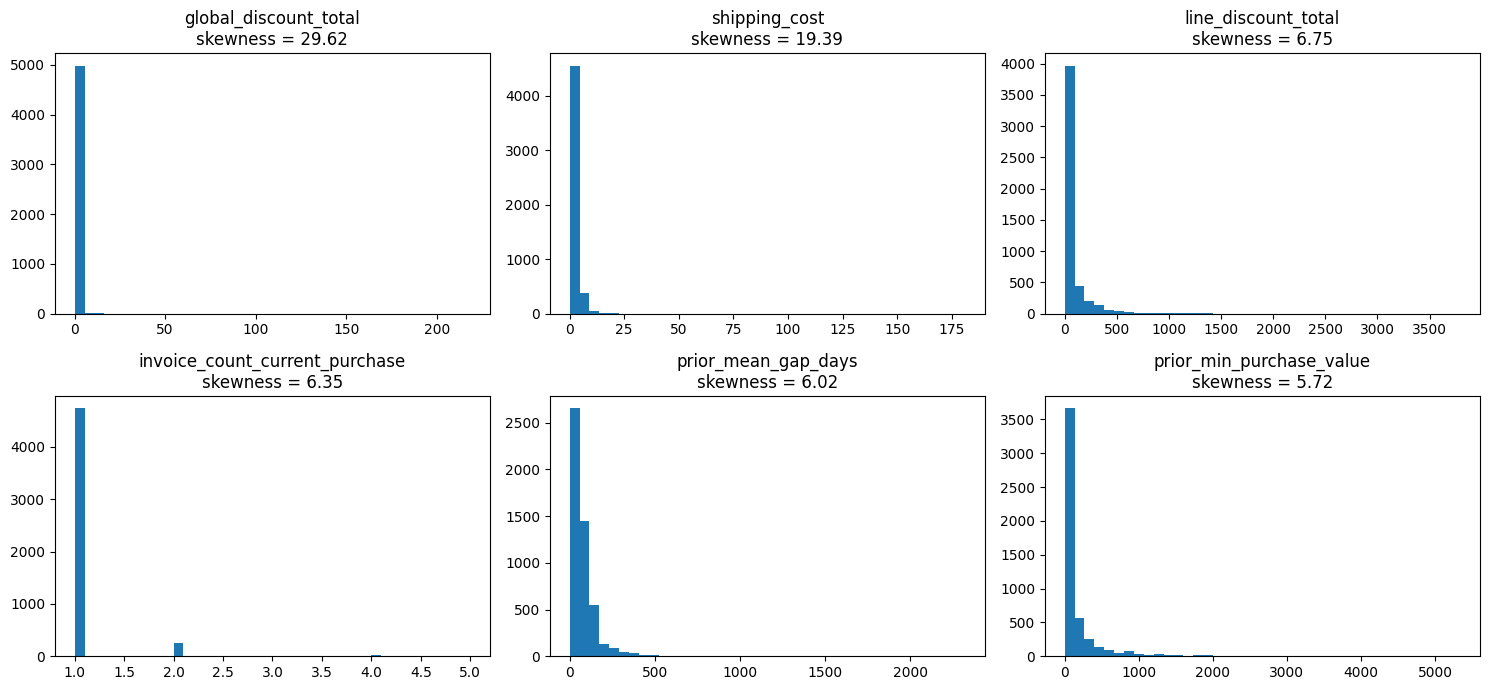


Largest values of global_discount_total


,id,customer_id,purchase_date,global_discount_total
6035,10007082,113110,2015-07-11,218.49
3496,10004096,529466,2023-03-18,184.40
593,10000690,952237,2022-02-26,115.88
4705,10005523,666120,2016-10-16,89.62
2400,10002808,667800,2021-03-06,65.68



Largest values of shipping_cost


,id,customer_id,purchase_date,shipping_cost
5542,10006514,849644,2021-01-11,181.06
665,10000776,717242,2019-02-23,159.73
4405,10005170,630646,2022-05-31,150.00
4810,10005654,117553,2021-10-23,150.00
2216,10002586,400536,2018-08-03,140.00



Largest values of line_discount_total


,id,customer_id,purchase_date,line_discount_total
3408,10003996,807493,2020-10-02,3794.51
1808,10002107,400536,2019-09-01,3720.00
3802,10004460,770941,2021-09-08,3704.89
2376,10002779,531725,2022-09-20,3434.18
5542,10006514,849644,2021-01-11,3386.82


... (2 outputs left out)


Largest values of prior_mean_gap_days


,id,customer_id,purchase_date,prior_mean_gap_days
3987,10004689,871761,2022-10-22,2324.0
4008,10004715,495202,2020-09-08,1435.0
5552,10006524,273298,2019-04-30,1284.0
3068,10003590,128695,2020-12-21,1057.0
5633,10006619,805495,2018-07-07,986.0



Largest values of prior_min_purchase_value


,id,customer_id,purchase_date,prior_min_purchase_value
2250,10002626,823441,2018-09-08,5340.24
3027,10003546,683049,2021-12-17,4935.79
2960,10003466,161053,2018-09-14,4718.65
5543,10006515,952237,2022-05-07,4608.71
5599,10006581,322897,2021-11-06,4435.66


In [6]:
top_columns = (
    outlier_report["absolute_skewness"]
    .sort_values(ascending=False)
    .head(6)
    .index
)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for column, axis in zip(top_columns, axes.flat):
    axis.hist(numeric_data[column].dropna(), bins=40)
    axis.set_title(
        f"{column}\nskewness = {outlier_report.loc[column, 'skewness']:.2f}"
    )
plt.tight_layout()
plt.show()

for column in top_columns:
    largest = extras_dev[["id", "customer_id", "purchase_date"]].copy()
    largest[column] = numeric_data[column]
    print(f"\nLargest values of {column}")
    display(largest.nlargest(5, column))

## 6. What do the algorithms actually flag?

IQR, Isolation Forest and LOF are compared on the same development rows. A 3% rate is used for the multivariate methods only to make their groups comparable. The target summaries reveal whether a method mainly selects useful high-value customers.

In [7]:
def method_flags(features, numeric_features):
    available = [column for column in numeric_features if column in features.columns]
    iqr_count = pd.Series(0, index=features.index)

    for column in available:
        values = features[column]
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr > 0:
            flag = values.lt(q1 - 1.5 * iqr) | values.gt(q3 + 1.5 * iqr)
            iqr_count += flag.fillna(False).astype(int)

    scaler = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler()),
    ])
    matrix = scaler.fit_transform(features[available])

    forest = IsolationForest(contamination=0.03, random_state=42)
    lof = LocalOutlierFactor(contamination=0.03)

    return pd.DataFrame({
        "IQR (3+ columns)": iqr_count.ge(3),
        "Isolation Forest": forest.fit_predict(matrix) == -1,
        "LOF": lof.fit_predict(matrix) == -1,
    }, index=features.index)

classification_flags = method_flags(X_dev, numeric_columns)

print("Rows flagged by each method")
display(classification_flags.mean().mul(100).round(2).rename("flagged_%"))
print("Pairwise overlap in rows")
display(classification_flags.astype(int).T.dot(classification_flags.astype(int)))

target_profiles = []
for method in classification_flags:
    flag = classification_flags[method]
    target_profiles.append({
        "method": method,
        "repeat rate — flagged": y_dev[flag].mean(),
        "repeat rate — other rows": y_dev[~flag].mean(),
    })
display(pd.DataFrame(target_profiles).set_index("method").round(3))

Rows flagged by each method


IQR (3+ columns)    25.26
Isolation Forest     3.01
LOF                  3.01
Name: flagged_%, dtype: float64

Pairwise overlap in rows


,IQR (3+ columns),Isolation Forest,LOF
IQR (3+ columns),1269,151,60
Isolation Forest,151,151,20
LOF,60,20,151


,repeat rate — flagged,repeat rate — other rows
method,,
IQR (3+ columns),0.774,0.474
Isolation Forest,0.854,0.540
LOF,0.464,0.552


## 7. Temporal validation setup

Both tasks use five expanding-window folds with the same 90-day gap as the project pipeline. This estimates performance on future purchases and keeps fitted preprocessing out of validation data.

In [8]:
def prepare_task(task, module, model_builder):
    rows = module.select_training_rows(train_clean, config)
    features, target, row_info = module.prepare_features(rows, config)
    features, _, target, _, row_info, _ = split_dev_test(
        features, target, row_info, config["test_set"], data_cfg["date_column"]
    )

    features = features.reset_index(drop=True)
    target = target.reset_index(drop=True)
    row_info = row_info.reset_index(drop=True)
    folds = temporal_folds(
        row_info[data_cfg["date_column"]],
        config["cv"]["n_splits"],
        config["cv"]["gap_days"],
    )

    return {
        "task": task,
        "X": features,
        "y": target,
        "folds": folds,
        "preprocessing": task_preprocessing_config(config, task),
        "model_builder": model_builder,
        "metric": config[task]["selection_metric"],
    }

task_data = {
    "classification": prepare_task(
        "classification", classification_prep, build_classifier
    ),
    "regression": prepare_task(
        "regression", regression_prep, build_regressor
    ),
}

for task, data in task_data.items():
    print(task, "development rows:", len(data["X"]))

classification development rows: 5024
regression development rows: 2659


## 8. Compare transformations

`log1p` is fitted only to non-negative columns whose training-fold skewness exceeds 2. Winsorisation learns its limits from each training fold. These are compared with no change and robust scaling.

In [9]:
class SkewLog1p(BaseEstimator, TransformerMixin):
    def __init__(self, columns, minimum_skew=2):
        self.columns = columns
        self.minimum_skew = minimum_skew

    def fit(self, X, y=None):
        self.columns_ = [
            column for column in self.columns
            if column in X and X[column].min() >= 0
            and abs(X[column].skew()) > self.minimum_skew
        ]
        return self

    def transform(self, X):
        result = X.copy()
        result[self.columns_] = np.log1p(result[self.columns_])
        return result


class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, columns, lower=0.01, upper=0.99):
        self.columns = columns
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        self.columns_ = [column for column in self.columns if column in X]
        self.lower_limits_ = X[self.columns_].quantile(self.lower)
        self.upper_limits_ = X[self.columns_].quantile(self.upper)
        return self

    def transform(self, X):
        result = X.copy()
        for column in self.columns_:
            result[column] = result[column].astype("float64").clip(
                self.lower_limits_[column], self.upper_limits_[column]
            )
        return result

In [10]:
def transformation_results(data):
    task = data["task"]
    prep_cfg = data["preprocessing"]
    numeric = prep_cfg["numeric_features"]
    recipes = {
        "No change": None,
        "log1p for skewed columns": SkewLog1p(numeric),
        "Winsorize 1%–99%": Winsorizer(numeric, 0.01, 0.99),
        "Winsorize 0.5%–99.5%": Winsorizer(numeric, 0.005, 0.995),
    }
    rows = []
    per_fold = {}

    for name, transformer in recipes.items():
        model = data["model_builder"](config[task]["model"])
        steps = [] if transformer is None else [("outlier_transform", transformer)]
        pipeline = Pipeline(steps + [
            ("prep", build_preprocessor(prep_cfg)),
            ("model", model),
        ])
        scores = cross_validate_pipeline(
            pipeline, data["X"], data["y"], data["folds"], SCORING[task]
        )
        values = scores[f"validation_{data['metric']}"].to_numpy()
        per_fold[name] = values
        rows.append({
            "task": task, "method": name,
            "mean_score": values.mean(),
            "fold_std": values.std(ddof=1),
        })

    robust_cfg = {**prep_cfg, "scaler": "robust"}
    robust_scores = cross_validate_pipeline(
        build_model_pipeline(
            robust_cfg, data["model_builder"](config[task]["model"])
        ),
        data["X"], data["y"], data["folds"], SCORING[task],
    )
    robust_values = robust_scores[f"validation_{data['metric']}"].to_numpy()
    per_fold["Robust scaler"] = robust_values
    rows.append({
        "task": task, "method": "Robust scaler",
        "mean_score": robust_values.mean(),
        "fold_std": robust_values.std(ddof=1),
    })

    baseline = per_fold["No change"]
    for row in rows:
        comparison = paired_comparison(
            per_fold[row["method"]], baseline, task == "classification"
        )
        row["mean_advantage"] = comparison["mean_advantage"]
        row["standard_error"] = comparison["se"]
        row["reliably_better"] = (
            comparison["mean_advantage"] > 2 * comparison["se"]
        )
    return rows

transformation_table = pd.DataFrame(
    transformation_results(task_data["classification"])
    + transformation_results(task_data["regression"])
)
display(transformation_table.round(4))

,task,method,mean_score,fold_std,mean_advantage,standard_error,reliably_better
0,classification,No change,0.7071,0.0172,0.0000,0.0000,False
1,classification,log1p for skewed columns,0.7140,0.0165,0.0069,0.0054,False
2,classification,Winsorize 1%–99%,0.7143,0.0086,0.0072,0.0047,False
3,classification,Winsorize 0.5%–99.5%,0.7119,0.0090,0.0048,0.0057,False
4,classification,Robust scaler,0.7057,0.0175,-0.0014,0.0023,False
5,regression,No change,1947.0557,164.5698,0.0000,0.0000,False
6,regression,log1p for skewed columns,1946.6959,164.4067,0.3598,0.1776,True
7,regression,Winsorize 1%–99%,1944.3471,162.2840,2.7085,2.6369,False
8,regression,Winsorize 0.5%–99.5%,1947.0918,165.1340,-0.0362,0.3646,False
9,regression,Robust scaler,1946.5356,165.2565,0.5200,0.3370,False


## 9. Compare row-removal methods

Each detector sees only a training fold. It may remove rows from that fold, but the following validation period is left complete. A method is only accepted if its average advantage is larger than twice its standard error.

In [11]:
def scaled_numeric_matrix(features, columns):
    available = [column for column in columns if column in features.columns]
    scaler = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", RobustScaler()),
    ])
    return scaler.fit_transform(features[available])


def rows_to_remove(features, numeric, method):
    if method == "No removal":
        return np.zeros(len(features), dtype=bool)

    if method == "IQR (3+ columns)":
        return method_flags(features, numeric)[method].to_numpy()

    matrix = scaled_numeric_matrix(features, numeric)

    if method == "Isolation Forest":
        return IsolationForest(
            contamination=0.03, random_state=42
        ).fit_predict(matrix) == -1

    if method == "LOF":
        return LocalOutlierFactor(contamination=0.03).fit_predict(matrix) == -1

    if method == "KNN distance":
        distances = NearestNeighbors(n_neighbors=11).fit(matrix).kneighbors(matrix)[0]
        score = distances[:, 1:].mean(axis=1)
        return score >= np.quantile(score, 0.97)

    if method == "K-Means distance":
        kmeans = KMeans(n_clusters=10, n_init=10, random_state=42).fit(matrix)
        score = np.linalg.norm(
            matrix - kmeans.cluster_centers_[kmeans.labels_], axis=1
        )
        return score >= np.quantile(score, 0.97)

    if method == "DBSCAN":
        distances = NearestNeighbors(n_neighbors=10).fit(matrix).kneighbors(matrix)[0]
        epsilon = np.quantile(distances[:, -1], 0.97)
        return DBSCAN(eps=epsilon, min_samples=10).fit_predict(matrix) == -1

    if method == "SOM distance":
        som = MiniSom(
            10, 10, matrix.shape[1], sigma=1, learning_rate=0.5, random_seed=42
        )
        som.random_weights_init(matrix)
        som.train_random(matrix, 1000)
        weights = som.get_weights()
        score = np.array([
            np.linalg.norm(row - weights[som.winner(row)]) for row in matrix
        ])
        return score >= np.quantile(score, 0.97)

    raise ValueError(f"Unknown method: {method}")

In [12]:
def evaluate_removal(data, method):
    task = data["task"]
    numeric = data["preprocessing"]["numeric_features"]
    scores = []
    removed = []

    for train_positions, validation_positions in data["folds"]:
        X_train = data["X"].iloc[train_positions]
        y_train = data["y"].iloc[train_positions]
        remove = rows_to_remove(X_train, numeric, method)
        removed.append(remove.mean() * 100)

        pipeline = build_model_pipeline(
            data["preprocessing"],
            data["model_builder"](config[task]["model"]),
        )
        pipeline.fit(X_train.loc[~remove], y_train.loc[~remove])
        predictions = pipeline.predict(data["X"].iloc[validation_positions])

        if task == "classification":
            score = accuracy_score(data["y"].iloc[validation_positions], predictions)
        else:
            score = mean_squared_error(
                data["y"].iloc[validation_positions], predictions
            ) ** 0.5
        scores.append(score)

    return np.array(scores), np.mean(removed)


removal_methods = [
    "No removal", "IQR (3+ columns)", "Isolation Forest", "LOF",
    "KNN distance", "K-Means distance", "DBSCAN", "SOM distance",
]
removal_rows = []

for task, data in task_data.items():
    results = {
        method: evaluate_removal(data, method) for method in removal_methods
    }
    baseline = results["No removal"][0]

    for method, (scores, removed_percent) in results.items():
        comparison = paired_comparison(
            scores, baseline, task == "classification"
        )
        removal_rows.append({
            "task": task,
            "method": method,
            "mean_score": scores.mean(),
            "fold_std": scores.std(ddof=1),
            "removed_%": removed_percent,
            "mean_advantage": comparison["mean_advantage"],
            "standard_error": comparison["se"],
            "folds_better": comparison["folds_a_better"],
            "reliably_better": (
                comparison["mean_advantage"] > 2 * comparison["se"]
            ),
        })

removal_table = pd.DataFrame(removal_rows)
display(removal_table.round(4))

,task,method,mean_score,fold_std,removed_%,mean_advantage,standard_error,folds_better,reliably_better
0,classification,No removal,0.7071,0.0172,0.0000,0.0000,0.0000,0,False
1,classification,IQR (3+ columns),0.7064,0.0183,23.8767,-0.0007,0.0065,3,False
2,classification,Isolation Forest,0.7066,0.0215,3.0327,-0.0005,0.0027,2,False
3,classification,LOF,0.7057,0.0180,3.0327,-0.0014,0.0033,3,False
4,classification,KNN distance,0.7069,0.0177,3.0327,-0.0002,0.0045,2,False
5,classification,K-Means distance,0.7019,0.0173,3.0327,-0.0053,0.0042,1,False
6,classification,DBSCAN,0.7040,0.0202,1.5993,-0.0031,0.0056,1,False
7,classification,SOM distance,0.7081,0.0215,3.0327,0.0010,0.0060,3,False
8,regression,No removal,1947.0557,164.5698,0.0000,0.0000,0.0000,0,False
9,regression,IQR (3+ columns),2180.8065,180.4348,25.2223,-233.7508,58.4519,0,False


## 10. DBSCAN sensitivity

DBSCAN needs an `eps` choice. The table shows how several reasonable choices change the result on the same development data. A stable natural cluster structure would not change this sharply.

In [13]:
matrix = scaled_numeric_matrix(X_dev, numeric_columns)
neighbour_distances = (
    NearestNeighbors(n_neighbors=10).fit(matrix).kneighbors(matrix)[0][:, -1]
)
dbscan_rows = []

for quantile in [0.90, 0.95, 0.97, 0.99]:
    epsilon = np.quantile(neighbour_distances, quantile)
    labels = DBSCAN(eps=epsilon, min_samples=10).fit_predict(matrix)
    cluster_count = len(set(labels)) - int(-1 in labels)
    dbscan_rows.append({
        "k-distance quantile": quantile,
        "eps": epsilon,
        "noise_%": np.mean(labels == -1) * 100,
        "clusters": cluster_count,
    })

display(pd.DataFrame(dbscan_rows).round(3))

,k-distance quantile,eps,noise_%,clusters
0,0.90,5.518,6.011,1
1,0.95,7.396,2.926,1
2,0.97,9.183,1.652,1
3,0.99,14.396,0.697,1


## 11. Method-by-method judgement

| Method | Judgement for this dataset |
|---|---|
| Logical consistency rules | **Use.** They identify impossible values from feature definitions, including `prior_max_purchase_value > prior_total_spend`. |
| IQR | Keep as a univariate diagnostic only. It fails on zero-heavy columns and removing rows flagged in 3+ columns seriously harms regression. |
| `log1p` | Plausible for skewed monetary values, but it does not reliably improve either task in temporal validation. |
| Winsorisation | Small classification changes and no reliable improvement; it also discards real magnitude information. Do not use. |
| Robust scaling | Useful in some settings, but it is not reliably better than the task-specific scalers already chosen. |
| Isolation Forest | The most reasonable optional multivariate **diagnostic**, but its flagged rows are often valuable high-repeat/high-spend customers and removal is not reliably better. |
| LOF / KNN distance | Sensitive to local density and the high-dimensional distance definition; no reliable validation gain. |
| DBSCAN | Finds one broad cluster plus a parameter-sensitive noise set; reasonable `eps` choices change the flagged share substantially. |
| K-Means distance | K-Means is a clustering method, not a natural outlier definition. The result depends on an arbitrary number of clusters and does not reliably improve prediction. |
| SOM distance | Useful for visual exploration, but map size, training and distance threshold are arbitrary; removal does not reliably improve prediction. |

## Final decision

1. **Correct genuine data errors with domain and consistency rules.** The new maximum-versus-total rule affects 45 train values and 6 test values. They become missing and are imputed inside the model pipeline.
2. **Keep statistically extreme but plausible observations.** They represent real high-value purchases and customers. No row-removal method gives a reliable temporal-validation improvement; IQR removal is particularly damaging for regression.
3. **Do not add `log1p`, winsorisation or a different scaler for outliers.** Their small changes are within fold uncertainty. The existing classification and regression recipes remain simpler and equally reliable.
4. **Use IQR and Isolation Forest only for investigation if new data arrives.** They may highlight rows for manual review, but they are not automatic deletion rules.

Therefore the final pipeline uses **rule-based correction plus no statistical outlier deletion or capping**. The locked period and `test.csv` remain untouched.